# UCS420: Cognitive Computing — Lab Assignment 9
## Vision based Cognitive Systems

---
### Student Information
- **Student Name:** Dhruv Singla
- **Roll Number:** 1024160007
- **Batch:** 3P11

**Objectives**
1. Design a cognitive assistant for reading medicine-bottle labels.
2. Design an emotion-aware cognitive assistant using facial-expression detection.

This notebook contains the design, executable Python implementations, example images, actual execution outputs, checks, and limitations for both tasks.

## Environment Setup
Run the cells in order using Python 3.10 or later in Jupyter or Google Colab. The example images are embedded in this notebook. Two small pretrained OpenCV models download automatically on the first run; subsequent runs use the local cache. OCR models are included with RapidOCR. No paid API or account is needed.

If imports fail, uncomment and run the installation line below, then restart the kernel. CPU inference is sufficient. The examples use pretrained models; neither task requires training a new network on this small demonstration set.

In [1]:
# Uncomment this line if the libraries are not installed:
# %pip install rapidocr-onnxruntime==1.4.4 "opencv-python>=4.10,<6" numpy matplotlib pillow

import base64
import hashlib
import io
import json
import re
from datetime import date
from pathlib import Path
from urllib.request import urlopen

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance, ImageFilter
from rapidocr_onnxruntime import RapidOCR
from IPython.display import display, Markdown

plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})
ROLL_NUMBER = 1024160007
np.random.seed(ROLL_NUMBER)
DATA_DIR = Path('assignment9_assets')
DATA_DIR.mkdir(exist_ok=True)
REFERENCE_DATE = date(2026, 11, 22)  # Fixed date makes the saved demo reproducible.
print('Student: Dhruv Singla | Roll number:', ROLL_NUMBER)
print('OpenCV:', cv2.__version__)

Student: Dhruv Singla | Roll number: 1024160007
OpenCV: 5.1.0


## Part I: Cognitive Assistant for Reading Medicine-Bottle Labels

### 1. System Design
**Image → text detection → OCR → structured field extraction → verification flags → answer.**

The perception component uses RapidOCR's pretrained text detector and recognizer. Each result contains a text box, recognized text, and a recognition score. A rule-based knowledge layer extracts the medicine name, strength, dosage form, batch, manufacture/expiry month, and storage text. The reasoning layer checks for missing fields and low OCR scores. The interaction layer answers questions using only extracted label content.

Recognition scores are model scores, not measured probabilities that a medical fact is correct. The assistant does not infer treatment, dosage, drug interactions, or whether a medicine is suitable for a patient. It requests label verification rather than inventing missing text.

### 2. Demonstration Data
The bottle below is a **synthetic educational test image**, created for this assignment with a fictional product, DEMOMED. Three controlled versions (original, reduced contrast, and slight blur) test the same label. These are not an independent real-world medicine dataset. The expiry assessment uses the fixed reference date above and is only a parser demonstration.

In [2]:
medicine_image = Image.open(io.BytesIO(base64.b64decode('...'))).convert('RGB')

In [3]:
face_image = Image.open(io.BytesIO(base64.b64decode('...'))).convert('RGB')

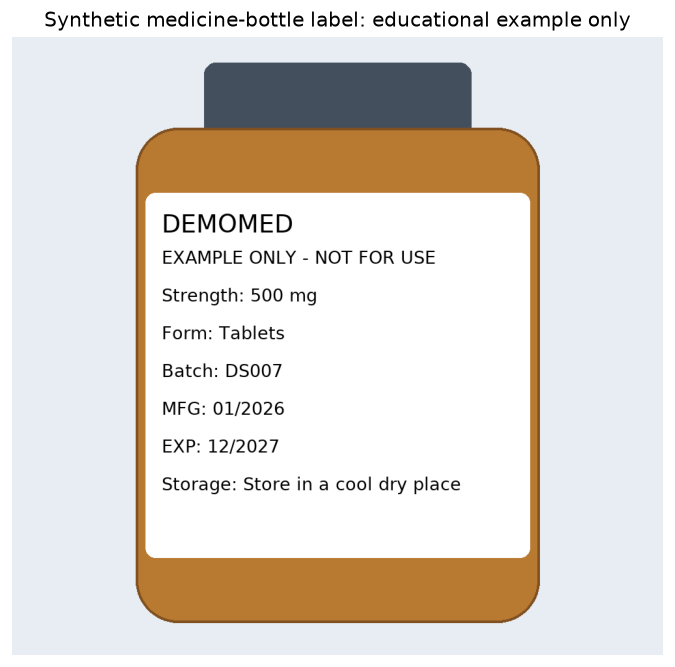

In [4]:
plt.figure(figsize=(7, 7))
plt.imshow(medicine_image)
plt.title('Synthetic medicine-bottle label: educational example only')
plt.axis('off')
plt.show()

### 3. Text Recognition and Field Extraction
Text is detected before recognition, so the assistant accepts a full bottle photograph rather than requiring manual entry of label text. Images are converted to RGB and enlarged when small; RapidOCR handles the detection and recognition preprocessing. Real photographs may additionally require perspective correction or multiple views of a curved label.

In [5]:
ocr_engine = RapidOCR(intra_op_num_threads=2, inter_op_num_threads=2)

def recognize_label(image):
    image = image.convert('RGB')
    if max(image.size) < 900:
        ratio = 900 / max(image.size)
        image = image.resize(tuple(round(v * ratio) for v in image.size))
    results, _ = ocr_engine(np.asarray(image))
    records = []
    for box, text, score in results or []:
        records.append({'box': np.asarray(box).tolist(),
                        'text': text.strip(), 'score': float(score)})
    return image, records

def extract_fields(records):
    lines = [r['text'] for r in records]
    full_text = '\n'.join(lines)
    fields = {}
    # This labeled-field parser supports the documented English label format.
    # Medicine-name extraction uses the first detected line as a candidate only.
    fields['medicine_name'] = lines[0] if lines else None
    patterns = {
        'strength': r'\b(\d+(?:\.\d+)?\s*(?:mg|mcg|g|ml)(?:\s*/\s*\d*\s*ml)?)\b',
        'dosage_form': r'\b(tablets?|capsules?|syrup|suspension|drops?)\b',
        'batch': r'\bBatch\s*[:.#-]?\s*([A-Z0-9-]+)',
        'manufactured': r'\bMFG\s*[:.-]?\s*(\d{2}\s*/\s*\d{4})',
        'expiry': r'\bEXP(?:IRY)?\s*[:.-]?\s*(\d{2}\s*/\s*\d{4})',
        'storage': r'\bStorage\s*[:.-]?\s*([^\n]+)',
    }
    for field, pattern in patterns.items():
        match = re.search(pattern, full_text, re.I)
        fields[field] = match.group(1).strip() if match else None
    return fields

def assess_label(records, fields, today=REFERENCE_DATE):
    flags = []
    if not records:
        return ['No readable text found. Retake a sharp, well-lit photograph.']
    if any(r['score'] < 0.85 for r in records):
        flags.append('Some OCR scores are low; verify the original label.')
    for field in ('medicine_name', 'strength', 'expiry'):
        if not fields.get(field):
            flags.append(f'{field} was not reliably extracted; verify manually.')
    if fields.get('expiry'):
        try:
            month, year = map(int, fields['expiry'].replace(' ', '').split('/'))
            date(year, month, 1)  # Validates the parsed month and year.
            if (year, month) < (today.year, today.month):
                flags.append('Parsed expiry month has passed; verify with a pharmacist.')
            else:
                flags.append('Parsed expiry month has not passed as of ' + str(today) + '.')
        except ValueError:
            flags.append('Expiry date is ambiguous; verify manually.')
    flags.append('OCR transcription only: verify every field on the original label.')
    return flags

def medicine_assistant(question, fields):
    q = question.lower()
    choices = [('expir', 'expiry'), ('strength', 'strength'),
               ('batch', 'batch'), ('stor', 'storage'),
               ('manufactur', 'manufactured'), ('name', 'medicine_name')]
    for keyword, field in choices:
        if keyword in q:
            value = fields.get(field)
            return (f'Label transcription — {field}: {value}. Verify on the bottle.'
                    if value else f'{field} was not extracted. Please verify the label.')
    return 'I can transcribe name, strength, batch, manufacture, expiry and storage. I cannot recommend a dose or treatment.'

processed_label, label_records = recognize_label(medicine_image)
label_fields = extract_fields(label_records)
print('RECOGNIZED LABEL TEXT')
for row in label_records:
    print(f"{row['score']:.3f} | {row['text']}")
print('\nSTRUCTURED FIELDS')
print(json.dumps(label_fields, indent=2))
print('\nVERIFICATION FLAGS')
for flag in assess_label(label_records, label_fields):
    print('-', flag)

RECOGNIZED LABEL TEXT
0.998 | DEMOMED
0.959 | EXAMPLE ONLY-NOT FOR USE
0.983 | Strength: 500 mg
0.983 | Form: Tablets
0.967 | Batch:DS007
0.994 | MFG: 01/2026
0.999 | EXP:12/2027
0.983 | Storage: Store in a cool dry place

STRUCTURED FIELDS
{
  "medicine_name": "DEMOMED",
  "strength": "500 mg",
  "dosage_form": "Tablets",
  "batch": "DS007",
  "manufactured": "01/2026",
  "expiry": "12/2027",
  "storage": "Store in a cool dry place"
}

VERIFICATION FLAGS
- Parsed expiry month has not passed as of 2026-11-22.
- OCR transcription only: verify every field on the original label.


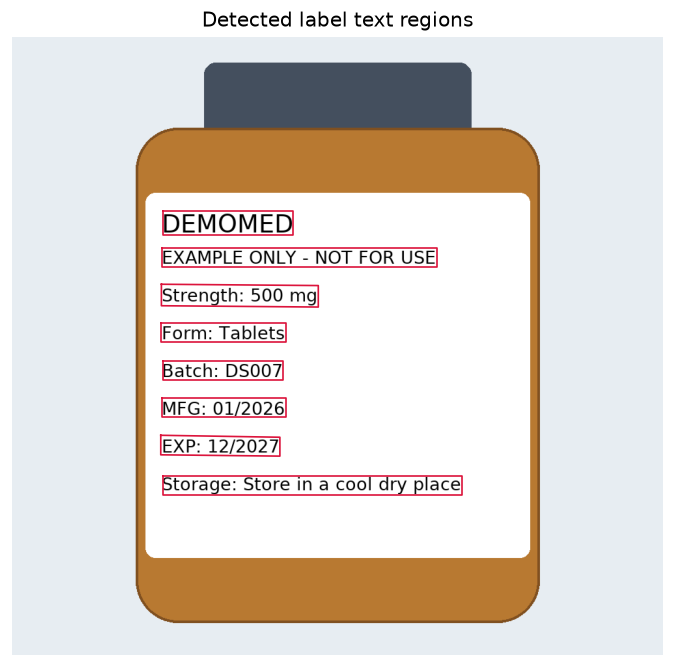

Question: What is the medicine name?
Assistant: Label transcription — medicine_name: DEMOMED. Verify on the bottle. 

Question: What is the strength?
Assistant: Label transcription — strength: 500 mg. Verify on the bottle. 

Question: When does it expire?
Assistant: Label transcription — expiry: 12/2027. Verify on the bottle. 

Question: How should I store it?
Assistant: Label transcription — storage: Store in a cool dry place. Verify on the bottle. 

Question: What dose should I take?
Assistant: I can transcribe name, strength, batch, manufacture, expiry and storage. I cannot recommend a dose or treatment. 



In [6]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(processed_label)
for record in label_records:
    box = np.asarray(record['box'])
    box = np.vstack([box, box[0]])
    ax.plot(box[:, 0], box[:, 1], color='crimson', linewidth=1)
ax.set_title('Detected label text regions')
ax.axis('off')
plt.show()

for question in ['What is the medicine name?', 'What is the strength?',
                 'When does it expire?', 'How should I store it?',
                 'What dose should I take?']:
    print('Question:', question)
    print('Assistant:', medicine_assistant(question, label_fields), '\n')

### 4. Controlled OCR Evaluation
The ground truth is the text used to create the synthetic label. Character error rate (CER) is Levenshtein edit distance divided by the reference character count; whitespace and letter case are normalized. Field accuracy checks the seven structured fields by exact normalized comparison. The same image under transformations is a robustness check, not evidence of generalization to unseen medicines.

In [7]:
def normalized(text):
    return re.sub(r'\s+', '', text).lower()

def edit_distance(a, b):
    previous = list(range(len(b) + 1))
    for i, char_a in enumerate(a, 1):
        current = [i]
        for j, char_b in enumerate(b, 1):
            current.append(min(current[-1] + 1, previous[j] + 1,
                               previous[j - 1] + (char_a != char_b)))
        previous = current
    return previous[-1]

reference_lines = ['DEMOMED', 'EXAMPLE ONLY - NOT FOR USE', 'Strength: 500 mg',
                   'Form: Tablets', 'Batch: DS007', 'MFG: 01/2026',
                   'EXP: 12/2027', 'Storage: Store in a cool dry place']
expected_fields = {'medicine_name': 'DEMOMED', 'strength': '500 mg',
                   'dosage_form': 'Tablets', 'batch': 'DS007',
                   'manufactured': '01/2026', 'expiry': '12/2027',
                   'storage': 'Store in a cool dry place'}
variants = {'Original': medicine_image,
            'Low contrast': ImageEnhance.Contrast(medicine_image).enhance(0.55),
            'Slight blur': medicine_image.filter(ImageFilter.GaussianBlur(0.8))}
reference = normalized(' '.join(reference_lines))
print(f"{'Test image':<17} {'CER':>8} {'Correct fields':>18}")
for name, image in variants.items():
    _, rows = recognize_label(image)
    fields = extract_fields(rows)
    prediction = normalized(' '.join(r['text'] for r in rows))
    cer = edit_distance(reference, prediction) / len(reference)
    correct = sum(normalized(fields.get(k) or '') == normalized(v)
                  for k, v in expected_fields.items())
    print(f'{name:<17} {cer:>8.3f} {correct:>15}/7')

assert assess_label([], {})[0].startswith('No readable text')
assert 'not extracted' in medicine_assistant('expiry?', {})
assert any('passed;' in s for s in assess_label(
    [{'score': 0.99}], {'medicine_name': 'Demo', 'strength': '1 mg', 'expiry': '01/2020'}))
print('\nEmpty-input, missing-field and expired-month checks passed.')

Test image             CER     Correct fields


Original             0.000               7/7


Low contrast         0.000               7/7


Slight blur          0.000               7/7

Empty-input, missing-field and expired-month checks passed.


## Part II: Emotion-Aware Cognitive Assistant

### 5. System Design
**Image → face detection → five-point alignment → expression classifier → uncertainty gate → optional supportive response.**

A pretrained **YuNet** detector finds face boxes and five facial landmarks. Landmarks align each face to the classifier's 112 × 112 input. OpenCV Zoo's **MobileFaceNet-based facial-expression model** produces seven expression scores: angry, disgust, fearful, happy, neutral, sad, and surprised. We convert logits to softmax scores and choose the largest score. A score below 0.60 produces an uncertain result rather than a firm label.

An observed expression is not proof of a person's internal emotional state. The assistant uses tentative language and asks the user to confirm. It does not diagnose mental health or make decisions about people. A camera application should require consent; the code below processes still images only and does not activate a webcam.

### 6. Pretrained Model Files
The models are downloaded from OpenCV's repositories, cached, and checked for their recorded SHA-256 digests. They run locally. The example is NASA's public-domain photograph of astronaut Eileen Collins, distributed by scikit-image; it is embedded above for portability. It has no ground-truth emotion label, so this example demonstrates inference rather than reporting classification accuracy.

In [8]:
MODEL_FILES = {'face_detection_yunet_2023mar.onnx': {'url': 'https://huggingface.co/opencv/face_detection_yunet/resolve/main/face_detection_yunet_2023mar.onnx', 'sha256': '8f2383e4dd3cfbb4553ea8718107fc0423210dc964f9f4280604804ed2552fa4'}, 'facial_expression_recognition_mobilefacenet_2022july.onnx': {'url': 'https://huggingface.co/opencv/facial_expression_recognition/resolve/main/facial_expression_recognition_mobilefacenet_2022july.onnx', 'sha256': '4f61307602fc089ce20488a31d4e4614e3c9753a7d6c41578c854858b183e1a9'}}

def ensure_model(name):
    info = MODEL_FILES[name]
    path = DATA_DIR / name
    if not path.exists():
        print('Downloading:', name)
        with urlopen(info['url'], timeout=90) as response:
            payload = response.read()
        if hashlib.sha256(payload).hexdigest() != info['sha256']:
            raise ValueError('Model checksum mismatch: ' + name)
        path.write_bytes(payload)
    if hashlib.sha256(path.read_bytes()).hexdigest() != info['sha256']:
        raise ValueError('Cached model checksum mismatch; remove and download again: ' + name)
    return str(path)

face_model_path = ensure_model('face_detection_yunet_2023mar.onnx')
expression_model_path = ensure_model('facial_expression_recognition_mobilefacenet_2022july.onnx')
face_detector = cv2.FaceDetectorYN.create(face_model_path, '', (320, 320), 0.85, 0.3, 5000)
expression_net = cv2.dnn.readNetFromONNX(expression_model_path)
EXPRESSION_LABELS = ['angry', 'disgust', 'fearful', 'happy', 'neutral', 'sad', 'surprised']
ALIGNMENT_TARGET = np.array([[38.2946, 51.6963], [73.5318, 51.5014],
                             [56.0252, 71.7366], [41.5493, 92.3655],
                             [70.7299, 92.2041]], dtype=np.float32)
print('Face detector and expression classifier loaded successfully.')

Face detector and expression classifier loaded successfully.


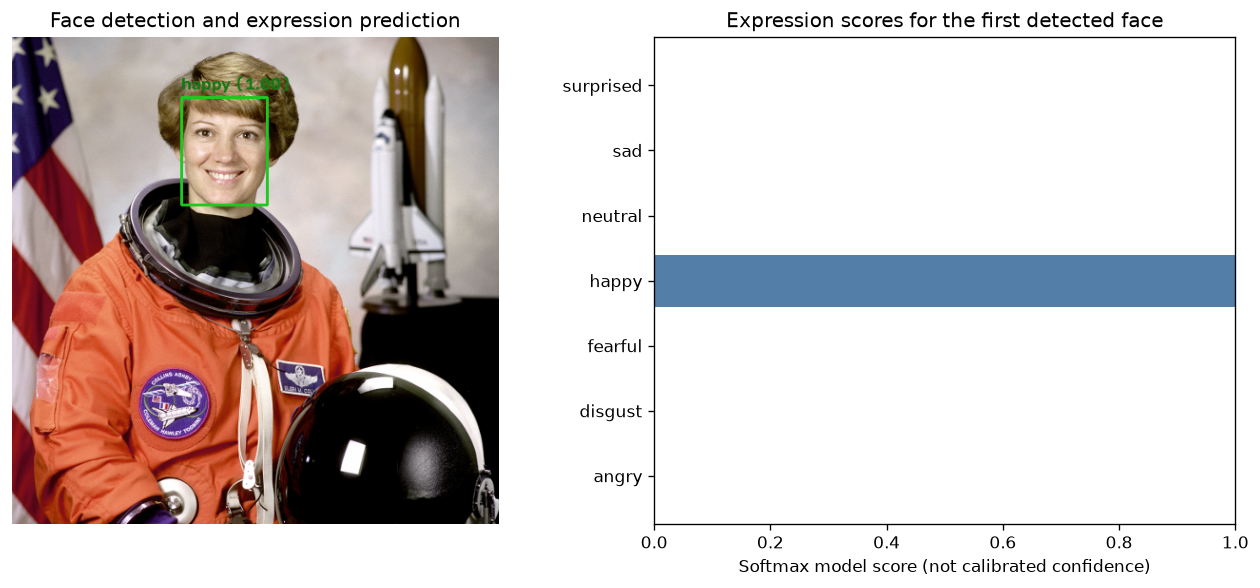

Faces detected: 1
Face 1: happy | score=1.000
Assistant: Your expression may look positive. Would you like to continue?


In [9]:
def aligned_face(image_bgr, detection):
    landmarks = np.asarray(detection[4:14], dtype=np.float32).reshape(5, 2)
    transform, _ = cv2.estimateAffinePartial2D(landmarks, ALIGNMENT_TARGET, method=cv2.LMEDS)
    if transform is None:
        raise ValueError('Could not align the detected face.')
    return cv2.warpAffine(image_bgr, transform, (112, 112))

def emotion_response(expression, score, threshold=0.60):
    if score < threshold or expression == 'uncertain':
        return 'I am unsure of the expression. How are you feeling, and how can I help?'
    responses = {
        'happy': 'Your expression may look positive. Would you like to continue?',
        'sad': 'Your expression may look sad. Would you like a pause or to talk?',
        'angry': 'Your expression may look tense. Would a short pause help?',
        'fearful': 'You may look concerned. Would you prefer a slower explanation?',
        'surprised': 'You may look surprised. Would you like me to explain that again?',
        'disgust': 'You may look uncomfortable. Would you like to change the topic?',
        'neutral': 'Would you like to continue or ask a question?'
    }
    return responses[expression]

def analyze_expressions(image, threshold=0.60):
    bgr = cv2.cvtColor(np.asarray(image.convert('RGB')), cv2.COLOR_RGB2BGR)
    height, width = bgr.shape[:2]
    face_detector.setInputSize((width, height))
    _, detections = face_detector.detect(bgr)
    annotated = bgr.copy()
    results = []
    for detection in [] if detections is None else detections:
        crop = aligned_face(bgr, detection)
        # Match the model's RGB, [-1, 1], NCHW input convention.
        rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB).astype(np.float32)
        tensor = ((rgb / 255.0 - 0.5) / 0.5).transpose(2, 0, 1)[None]
        expression_net.setInput(tensor, 'data')
        logits = expression_net.forward().reshape(-1)
        scores = np.exp(logits - logits.max())
        scores /= scores.sum()
        best = int(scores.argmax())
        candidate, score = EXPRESSION_LABELS[best], float(scores[best])
        expression = candidate if score >= threshold else 'uncertain'
        x, y, w, h = np.rint(detection[:4]).astype(int)
        cv2.rectangle(annotated, (x, y), (x + w, y + h), (30, 200, 30), 2)
        cv2.putText(annotated, f'{expression} ({score:.2f})', (max(0, x), max(18, y - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (20, 120, 20), 2)
        results.append({'expression': expression, 'top_candidate': candidate,
                        'model_score': score, 'face_detection_score': float(detection[-1]),
                        'all_scores': dict(zip(EXPRESSION_LABELS, map(float, scores))),
                        'response': emotion_response(expression, score, threshold),
                        'aligned_face': cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)})
    return cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB), results

annotated_face, expression_results = analyze_expressions(face_image)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(annotated_face)
axes[0].set_title('Face detection and expression prediction')
axes[0].axis('off')
if expression_results:
    result = expression_results[0]
    axes[1].barh(EXPRESSION_LABELS, list(result['all_scores'].values()), color='#527ea7')
    axes[1].set_xlim(0, 1)
    axes[1].set_xlabel('Softmax model score (not calibrated confidence)')
    axes[1].set_title('Expression scores for the first detected face')
else:
    axes[1].axis('off')
    axes[1].text(0, 0.5, 'No face detected. Please provide another image.')
plt.tight_layout()
plt.show()
print('Faces detected:', len(expression_results))
for i, result in enumerate(expression_results, 1):
    print(f"Face {i}: {result['expression']} | score={result['model_score']:.3f}")
    print('Assistant:', result['response'])

### 7. Behavior Checks and Evaluation Plan
The following checks validate blank-image handling, score normalization, and the uncertainty gate. Scripted response-policy examples exercise all seven branches; their scores are deliberately supplied test inputs, not measured model predictions.

To measure actual classifier performance, obtain a separately labeled, consented facial-expression test set, keep people disjoint between train and test splits, and report per-class precision/recall, macro-F1, and a confusion matrix. Report results across lighting, pose and demographic subgroups. No test-set accuracy is claimed here because the provided example has no verified expression label. The 0.60 gate is illustrative and would require validation and calibration before deployment.

In [10]:
blank = Image.new('RGB', (512, 512), 'white')
_, blank_results = analyze_expressions(blank)
assert blank_results == []
assert 'unsure' in emotion_response('happy', 0.2)
for result in expression_results:
    assert np.isclose(sum(result['all_scores'].values()), 1.0)
    assert 0 <= result['model_score'] <= 1
print('No-face handling, uncertainty gate and score-normalization checks passed.')
print('\nRESPONSE POLICY EXAMPLES (scripted score = 0.90)')
for expression in EXPRESSION_LABELS:
    print(f'{expression:10s}: {emotion_response(expression, 0.90)}')

No-face handling, uncertainty gate and score-normalization checks passed.

RESPONSE POLICY EXAMPLES (scripted score = 0.90)
angry     : Your expression may look tense. Would a short pause help?
disgust   : You may look uncomfortable. Would you like to change the topic?
fearful   : You may look concerned. Would you prefer a slower explanation?
happy     : Your expression may look positive. Would you like to continue?
neutral   : Would you like to continue or ask a question?
sad       : Your expression may look sad. Would you like a pause or to talk?
surprised : You may look surprised. Would you like me to explain that again?


## Part III: Use Your Own Images
Set either path below to a local JPG or PNG and rerun the cell. Leave a path as `None` to skip it. For a medicine bottle, use a sharp, upright English label with visible field names; the rule-based extractor may need extension for different layouts, languages, or date formats. For facial expressions, use images only with the person's permission. Images are processed locally and are not uploaded by these functions.

In [11]:
MEDICINE_IMAGE_PATH = None  # Example: 'my_bottle.jpg'
FACE_IMAGE_PATH = None      # Example: 'my_face.jpg'

if MEDICINE_IMAGE_PATH:
    with Image.open(MEDICINE_IMAGE_PATH) as image:
        _, records = recognize_label(image)
    fields = extract_fields(records)
    print(json.dumps(fields, indent=2))
    for message in assess_label(records, fields, today=date.today()):
        print('-', message)

if FACE_IMAGE_PATH:
    with Image.open(FACE_IMAGE_PATH) as image:
        annotated, results = analyze_expressions(image)
    plt.figure(figsize=(7, 5))
    plt.imshow(annotated)
    plt.axis('off')
    plt.show()
    if not results:
        print('No face detected. Please try a clearer image.')
    for result in results:
        print(result['response'])

## Discussion and Conclusion

| Component | Implemented behavior | Main limitation |
|---|---|---|
| Label perception | Text detection, recognition and bounding boxes | Glare, curvature, handwriting and small print can cause errors |
| Label reasoning | Field extraction, missing-field flags and expiry-month comparison | English labeled formats only; the first line is merely a name candidate |
| Label interaction | Answers drawn from extracted content | Cannot recommend medication, dosage or treatment |
| Face perception | YuNet detection and five-landmark alignment | Occlusion, pose and lighting can prevent reliable detection |
| Expression reasoning | Seven-class inference and uncertainty threshold | Visible expression cannot establish internal emotion |
| Adaptive interaction | Tentative responses and user confirmation | Response rules are a small demonstration, not a clinical intervention |

Both assistants combine **perception**, **structured interpretation**, **reasoning under uncertainty**, and **user interaction**. The notebook demonstrates end-to-end inference with saved outputs rather than claiming that these prototypes are ready for medical or psychological use. Further work would collect diverse labeled images, evaluate held-out performance, calibrate scores, extend the label parser and test accessibility with users.

## References and Attribution
- Assignment brief: *Lab Assignment-9 — Cognitive Computing UCS420, Landing AI (Vision based Cognitive System)*, supplied PDF.
- [RapidOCR project and documentation](https://github.com/RapidAI/RapidOCR): pretrained OCR implementation; installed package `rapidocr-onnxruntime==1.4.4`. Project and underlying PaddleOCR model licensing is described by the authors.
- [OpenCV Zoo: YuNet face detector](https://github.com/opencv/opencv_zoo/tree/main/models/face_detection_yunet): model, usage and model-specific license.
- [OpenCV Zoo: Facial expression recognition](https://github.com/opencv/opencv_zoo/tree/main/models/facial_expression_recognition): MobileFaceNet-based seven-class model, input preprocessing, label order and model-specific license. Pretrained weights are downloaded, not authored or trained here.
- [scikit-image astronaut sample](https://scikit-image.org/docs/stable/api/skimage.data.html#skimage.data.astronaut): NASA public-domain portrait of Eileen Collins, distributed in scikit-image; embedded for the face demonstration.
- Synthetic medicine-bottle test image and its ground truth were created for this notebook; DEMOMED is fictional.